In [40]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F

from flower_categories import flower_names
from torch import nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from scipy.io import loadmat

In [2]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

dataset = datasets.Flowers102(
    root="./data",
    split="train",
    download=True,
    transform=transform
)

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=False,
)

100%|██████████| 344862509/344862509 [00:31<00:00, 10818653.48it/s]


Extracting data\flowers-102\102flowers.tgz to data\flowers-102


100%|██████████| 502/502 [00:00<00:00, 501916.71it/s]


100%|██████████| 14989/14989 [00:00<00:00, 7501303.26it/s]


In [36]:
image, label = dataset[200]

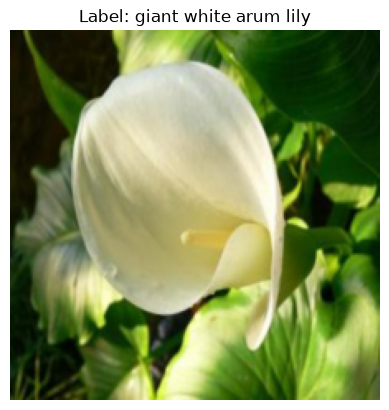

In [38]:
image = image.permute(1,2,0)

plt.imshow(image)
plt.title(f"Label: {flower_names[label+1]}")
plt.axis("off")
plt.show()

In [ ]:
class DenseLayer(nn.Module):
    def __init__(self, in_channels, growth_rate):
        super(DenseLayer, self).__init__()
        self.bn = nn.BatchNorm2d(in_channels)
        self.conv = nn.Conv2d(in_channels, growth_rate, kernel_size=3, stride=1, padding=1, bias=False)
        
    def forward(self, x):
        out = self.conv(F.relu(self.bn(x)))
        return torch.cat([x, out], dim=1)

class DenseBlock(nn.Module):
    def __init__(self, num_layers, in_channels, growth_rate):
        super(DenseBlock, self).__init__()
        self.layers = nn.ModuleList()
        current_channels = in_channels
        
        for _ in range(num_layers):
            self.layers.append(DenseLayer(current_channels, growth_rate))
            current_channels += growth_rate
            
        def forward(self, x):
            for layer in self.layers:
                x = layer(x)
            return x

class TransitionLayer(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(TransitionLayer, self).__init__()
        self.bn = nn.BatchNorm2d(in_channels)
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=1, bias=False)
        self.pool = nn.AvgPool2d(kernel_size=2, stride=2)
    
    def forward(self, x):
        out = self.pool(self.conv(F.relu(self.bn(x))))
        return out
        

class FlowersDenseNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=102, growth_rate=32):
        super(FlowersDenseNet, self).__init__()
        
        self.init_conv = nn.Sequential(
            nn.Conv2d(in_channels=in_channels, out_channels=64, kernel_size=7, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(64)
            nn.ReLU(inplace=True)
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )
        
        self.block1 = DenseBlock(num_layers)
        
        
        
        